In [1]:
# ============================================================
# CELL 1: IMPORT VÀ ĐỌC 4 FILE SPLIT
# ============================================================

import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve,
)
import matplotlib.pyplot as plt
import os

# Đường dẫn (tính từ src/)
SPLIT_DIR = "../data/splits/"
MODEL_DIR = "../models/"

# Đọc 4 file
X_train = pd.read_csv(f"{SPLIT_DIR}X_train.csv")
y_train = pd.read_csv(f"{SPLIT_DIR}y_train.csv").squeeze("columns")
X_test  = pd.read_csv(f"{SPLIT_DIR}X_test.csv")
y_test  = pd.read_csv(f"{SPLIT_DIR}y_test.csv").squeeze("columns")

print("=" * 60)
print("ĐỌC 4 FILE SPLIT")
print("=" * 60)
print(f"X_train: {X_train.shape}")
print(f"y_train: {y_train.shape}")
print(f"X_test : {X_test.shape}")
print(f"y_test : {y_test.shape}")

# Kiểm tra NaN ở y
print(f"\nNaN ở y_train: {y_train.isna().sum()}")
print(f"NaN ở y_test : {y_test.isna().sum()}")

# Phân bố nhãn
print(f"\nPhân bố nhãn TRAIN:")
print(y_train.value_counts().to_string())
print(f"\nPhân bố nhãn TEST:")
print(y_test.value_counts().to_string())

# Kiểm tra kiểu dữ liệu
print(f"\nSố đặc trưng: {X_train.shape[1]}")
print(f"Cột X_train: {list(X_train.columns)[:5]}...")

ĐỌC 4 FILE SPLIT
X_train: (1860, 23)
y_train: (1860,)
X_test : (466, 23)
y_test : (466,)

NaN ở y_train: 0
NaN ở y_test : 0

Phân bố nhãn TRAIN:
mortality
0    1707
1     153

Phân bố nhãn TEST:
mortality
0    428
1     38

Số đặc trưng: 23
Cột X_train: ['age', 'male_sex', 'bmi', 'gcs', 'heartrate_mean']...


In [3]:
# ============================================================
# CELL 2: KHỞI TẠO VÀ HUẤN LUYỆN XGBOOST
# ============================================================

# ---------- Tính scale_pos_weight từ y_train ----------
n_alive_train   = (y_train == 0).sum()
n_expired_train = (y_train == 1).sum()
scale_pos_weight = n_alive_train / n_expired_train

print("=" * 60)
print("KHỞI TẠO XGBOOST")
print("=" * 60)
print(f"scale_pos_weight = {scale_pos_weight:.4f} "
      f"(= {n_alive_train} / {n_expired_train})")

# ---------- Khởi tạo mô hình ----------
model = xgb.XGBClassifier(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.05,
    scale_pos_weight=scale_pos_weight,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1,             # dùng tất cả CPU core
)

print(f"\nSiêu tham số:")
print(f"  n_estimators      = {model.n_estimators}")
print(f"  max_depth         = {model.max_depth}")
print(f"  learning_rate     = {model.learning_rate}")
print(f"  scale_pos_weight  = {model.scale_pos_weight:.4f}")

# ---------- Huấn luyện ----------
print(f"\nĐang huấn luyện...")
model.fit(X_train, y_train)
print(f"✅ Huấn luyện xong!")

# ---------- Dự đoán xác suất trên test ----------
y_pred_proba = model.predict_proba(X_test)[:, 1]

print(f"\nThống kê xác suất dự đoán trên test:")
print(f"  min  = {y_pred_proba.min():.4f}")
print(f"  mean = {y_pred_proba.mean():.4f}")
print(f"  max  = {y_pred_proba.max():.4f}")

# So sánh với nhãn thật
print(f"\nXác suất trung bình theo nhãn thật:")
print(f"  Alive   (y=0): {y_pred_proba[y_test == 0].mean():.4f}")
print(f"  Expired (y=1): {y_pred_proba[y_test == 1].mean():.4f}")
print(f"  → Nếu nhóm Expired có xác suất cao hơn rõ rệt, mô hình học tốt.")

KHỞI TẠO XGBOOST
scale_pos_weight = 11.1569 (= 1707 / 153)

Siêu tham số:
  n_estimators      = 100
  max_depth         = 3
  learning_rate     = 0.05
  scale_pos_weight  = 11.1569

Đang huấn luyện...
✅ Huấn luyện xong!

Thống kê xác suất dự đoán trên test:
  min  = 0.0111
  mean = 0.2891
  max  = 0.9767

Xác suất trung bình theo nhãn thật:
  Alive   (y=0): 0.2616
  Expired (y=1): 0.5988
  → Nếu nhóm Expired có xác suất cao hơn rõ rệt, mô hình học tốt.


In [4]:
# ============================================================
# CELL 3: ĐÁNH GIÁ AUROC, AUPRC + BOOTSTRAP 95% CI
# ============================================================

# ---------- Tính AUROC, AUPRC trên tập test ----------
auroc = roc_auc_score(y_test, y_pred_proba)
auprc = average_precision_score(y_test, y_pred_proba)

print("=" * 60)
print("ĐÁNH GIÁ TRÊN TẬP TEST")
print("=" * 60)
print(f"AUROC : {auroc:.4f}  (bài báo: ~0.855)")
print(f"AUPRC : {auprc:.4f}  (bài báo: ~0.332)")
print(f"Tỷ lệ tử vong test: {y_test.mean()*100:.2f}% "
      f"(baseline AUPRC = {y_test.mean():.4f})")

# ---------- Bootstrap 95% CI ----------
N_BOOTSTRAP = 1000
np.random.seed(42)

auroc_boot = np.zeros(N_BOOTSTRAP)
auprc_boot = np.zeros(N_BOOTSTRAP)

n_test = len(y_test)
y_test_arr = y_test.values
y_pred_arr = y_pred_proba

print(f"\nĐang bootstrap {N_BOOTSTRAP} lần...")
for i in range(N_BOOTSTRAP):
    # Rút mẫu có thay thế
    idx = np.random.choice(n_test, size=n_test, replace=True)
    y_boot = y_test_arr[idx]
    pred_boot = y_pred_arr[idx]

    # Bỏ qua nếu mẫu bootstrap chỉ có 1 lớp
    if len(np.unique(y_boot)) < 2:
        auroc_boot[i] = np.nan
        auprc_boot[i] = np.nan
        continue

    auroc_boot[i] = roc_auc_score(y_boot, pred_boot)
    auprc_boot[i] = average_precision_score(y_boot, pred_boot)

# ---------- Tính CI 95% (percentile 2.5 và 97.5) ----------
auroc_ci_low,  auroc_ci_high = np.nanpercentile(auroc_boot, [2.5, 97.5])
auprc_ci_low,  auprc_ci_high = np.nanpercentile(auprc_boot, [2.5, 97.5])

print("=" * 60)
print("KẾT QUẢ ĐÁNH GIÁ (95% CI)")
print("=" * 60)
print(f"AUROC : {auroc:.4f}  (95% CI: {auroc_ci_low:.4f} – {auroc_ci_high:.4f})")
print(f"AUPRC : {auprc:.4f}  (95% CI: {auprc_ci_low:.4f} – {auprc_ci_high:.4f})")

print(f"\nSo sánh với bài báo:")
print(f"  AUROC bài báo: 0.855 (CI: 0.796 – 0.906)")
print(f"  AUPRC bài báo: 0.332 (CI: 0.217 – 0.494)")

# ---------- Kiểm tra bootstrap hợp lệ ----------
n_valid = (~np.isnan(auroc_boot)).sum()
print(f"\nSố mẫu bootstrap hợp lệ: {n_valid}/{N_BOOTSTRAP}")

ĐÁNH GIÁ TRÊN TẬP TEST
AUROC : 0.8178  (bài báo: ~0.855)
AUPRC : 0.3989  (bài báo: ~0.332)
Tỷ lệ tử vong test: 8.15% (baseline AUPRC = 0.0815)

Đang bootstrap 1000 lần...
KẾT QUẢ ĐÁNH GIÁ (95% CI)
AUROC : 0.8178  (95% CI: 0.7360 – 0.8833)
AUPRC : 0.3989  (95% CI: 0.2469 – 0.5615)

So sánh với bài báo:
  AUROC bài báo: 0.855 (CI: 0.796 – 0.906)
  AUPRC bài báo: 0.332 (CI: 0.217 – 0.494)

Số mẫu bootstrap hợp lệ: 1000/1000


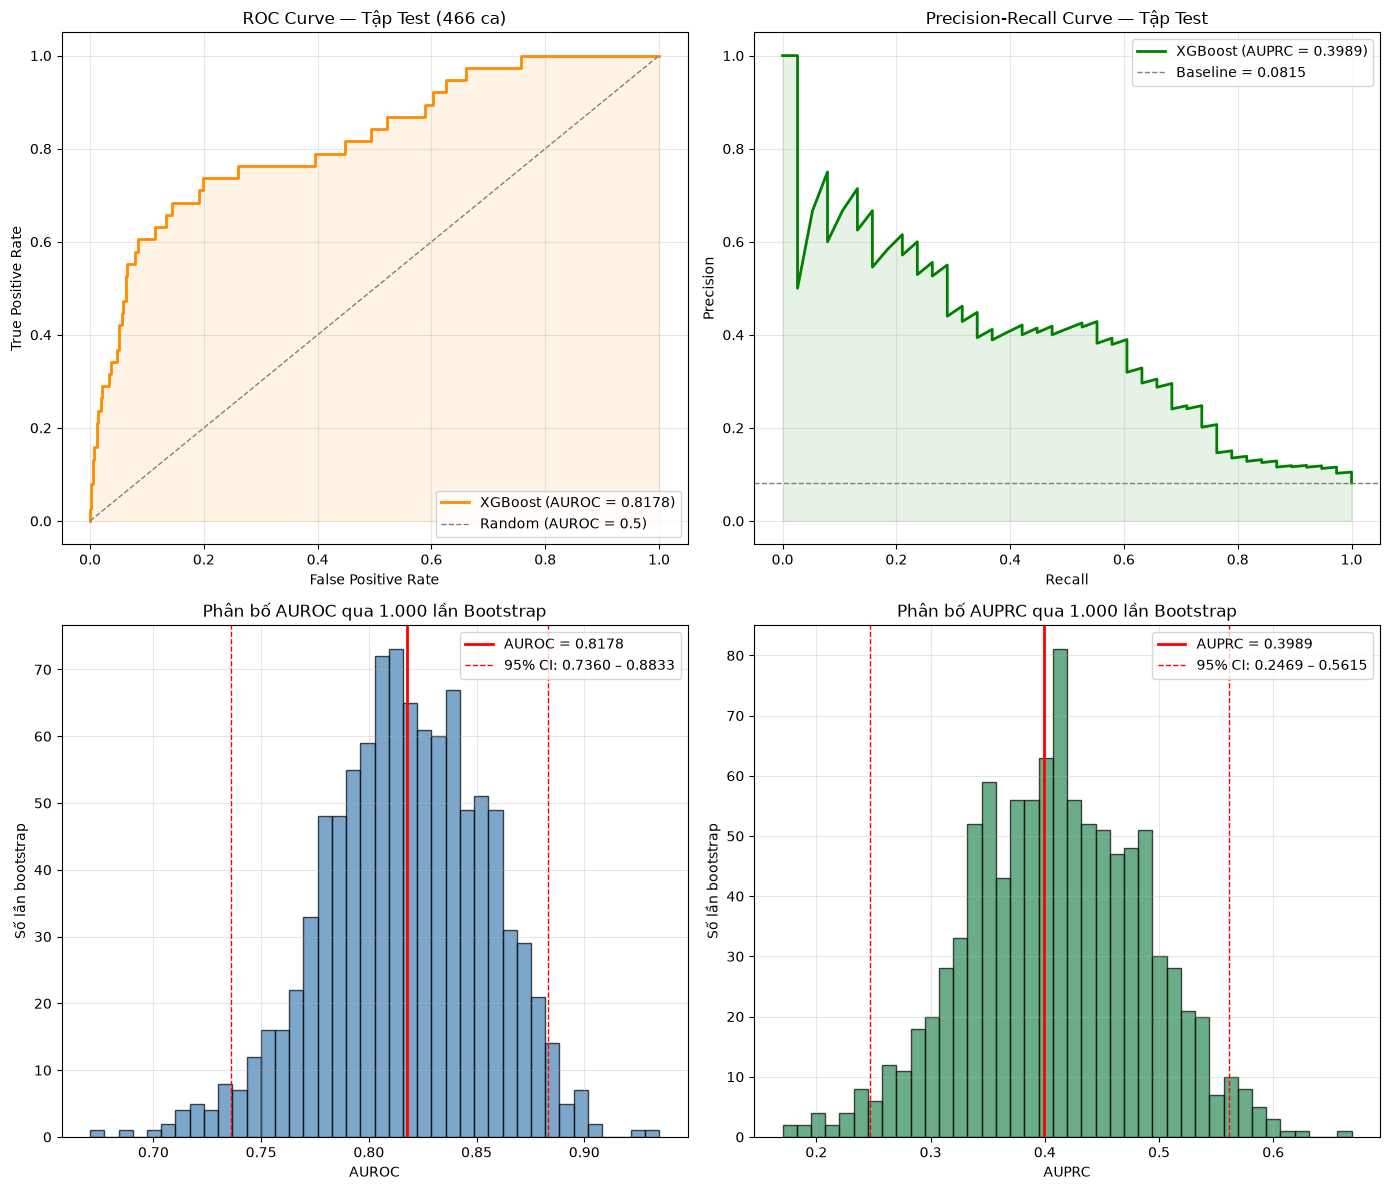

✅ Đã lưu biểu đồ: ../outputs/plots/xgboost_evaluation.png


In [5]:
# ============================================================
# CELL 4: VẼ ROC, PR CURVE VÀ PHÂN BỐ BOOTSTRAP
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(14, 12))

# ---------- 1. ROC Curve ----------
fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
axes[0, 0].plot(fpr, tpr, color="darkorange", lw=2,
                label=f"XGBoost (AUROC = {auroc:.4f})")
axes[0, 0].plot([0, 1], [0, 1], color="gray", lw=1,
                linestyle="--", label="Random (AUROC = 0.5)")
axes[0, 0].fill_between(fpr, tpr, alpha=0.1, color="darkorange")
axes[0, 0].set_xlabel("False Positive Rate")
axes[0, 0].set_ylabel("True Positive Rate")
axes[0, 0].set_title("ROC Curve — Tập Test (466 ca)")
axes[0, 0].legend(loc="lower right")
axes[0, 0].grid(alpha=0.3)

# ---------- 2. PR Curve ----------
precision, recall, _ = precision_recall_curve(y_test, y_pred_proba)
baseline = y_test.mean()
axes[0, 1].plot(recall, precision, color="green", lw=2,
                label=f"XGBoost (AUPRC = {auprc:.4f})")
axes[0, 1].axhline(baseline, color="gray", lw=1,
                   linestyle="--", label=f"Baseline = {baseline:.4f}")
axes[0, 1].fill_between(recall, precision, alpha=0.1, color="green")
axes[0, 1].set_xlabel("Recall")
axes[0, 1].set_ylabel("Precision")
axes[0, 1].set_title("Precision-Recall Curve — Tập Test")
axes[0, 1].legend(loc="upper right")
axes[0, 1].grid(alpha=0.3)

# ---------- 3. Phân bố bootstrap AUROC ----------
axes[1, 0].hist(auroc_boot, bins=40, color="steelblue",
                edgecolor="black", alpha=0.7)
axes[1, 0].axvline(auroc, color="red", lw=2,
                   label=f"AUROC = {auroc:.4f}")
axes[1, 0].axvline(auroc_ci_low, color="red", lw=1, linestyle="--",
                   label=f"95% CI: {auroc_ci_low:.4f} – {auroc_ci_high:.4f}")
axes[1, 0].axvline(auroc_ci_high, color="red", lw=1, linestyle="--")
axes[1, 0].set_xlabel("AUROC")
axes[1, 0].set_ylabel("Số lần bootstrap")
axes[1, 0].set_title("Phân bố AUROC qua 1.000 lần Bootstrap")
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)

# ---------- 4. Phân bố bootstrap AUPRC ----------
axes[1, 1].hist(auprc_boot, bins=40, color="seagreen",
                edgecolor="black", alpha=0.7)
axes[1, 1].axvline(auprc, color="red", lw=2,
                   label=f"AUPRC = {auprc:.4f}")
axes[1, 1].axvline(auprc_ci_low, color="red", lw=1, linestyle="--",
                   label=f"95% CI: {auprc_ci_low:.4f} – {auprc_ci_high:.4f}")
axes[1, 1].axvline(auprc_ci_high, color="red", lw=1, linestyle="--")
axes[1, 1].set_xlabel("AUPRC")
axes[1, 1].set_ylabel("Số lần bootstrap")
axes[1, 1].set_title("Phân bố AUPRC qua 1.000 lần Bootstrap")
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# ---------- Lưu biểu đồ (tùy chọn) ----------
os.makedirs("../outputs/plots/", exist_ok=True)
fig.savefig("../outputs/plots/xgboost_evaluation.png", dpi=150,
            bbox_inches="tight")
print("✅ Đã lưu biểu đồ: ../outputs/plots/xgboost_evaluation.png")

In [6]:
# ============================================================
# CELL 5: LƯU MODEL
# ============================================================

# Tạo thư mục models/ nếu chưa có
os.makedirs("../models/", exist_ok=True)

# Lưu model
MODEL_PATH = "../models/xgboost_model.json"
model.save_model(MODEL_PATH)

print("=" * 60)
print("LƯU MODEL")
print("=" * 60)
print(f"✅ Đã lưu: {MODEL_PATH}")
print(f"   Kích thước file: {os.path.getsize(MODEL_PATH) / 1024:.1f} KB")

# ---------- Kiểm tra đọc lại ----------
print(f"\nKiểm tra đọc lại model:")
model_loaded = xgb.XGBClassifier()
model_loaded.load_model(MODEL_PATH)

# Dự đoán lại trên test để so sánh
y_pred_proba_loaded = model_loaded.predict_proba(X_test)[:, 1]

# So sánh với dự đoán gốc
diff = np.abs(y_pred_proba - y_pred_proba_loaded).max()
print(f"  Số đặc trưng model đọc lại: {model_loaded.n_features_in_}")
print(f"  Chênh lệch dự đoán tối đa: {diff:.10f}")
print(f"  {'✅ Model đọc lại khớp hoàn toàn' if diff < 1e-6 else '⚠️ Có sai lệch!'}")

# ---------- Tóm tắt artifacts ----------
print(f"\n" + "=" * 60)
print("TÓM TẮT ARTIFACTS ĐÃ LƯU")
print("=" * 60)
print(f"  Model        : {MODEL_PATH}")
print(f"\n→ Sẵn sàng cho bước SHAP và LLM/Agentic pipeline!")

LƯU MODEL
✅ Đã lưu: ../models/xgboost_model.json
   Kích thước file: 116.0 KB

Kiểm tra đọc lại model:
  Số đặc trưng model đọc lại: 23
  Chênh lệch dự đoán tối đa: 0.0000000000
  ✅ Model đọc lại khớp hoàn toàn

TÓM TẮT ARTIFACTS ĐÃ LƯU
  Model        : ../models/xgboost_model.json
  X_test       : ../data/splits/X_test.csv
  y_test       : ../data/splits/y_test.csv
  Biểu đồ      : ../outputs/plots/xgboost_evaluation.png

→ Sẵn sàng cho bước SHAP và LLM/Agentic pipeline!
